# Análise Exploratória de Dados: NPS e Experiência do Cliente

Neste notebook, olhamos para os dados da jornada de compra para entender o que aparece junto com uma experiência melhor ou pior. Primeiro, conhecemos a base; depois, passamos por logística, atendimento, perfil do cliente e recompra. A ideia é responder às perguntas do desafio sem esquecer as limitações dos dados.

## 1. Bibliotecas e configuração

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal, spearmanr

## 2. Preparação dos dados

### 2.1 Carregamento e inspeção inicial

In [2]:
df = pd.read_csv('../data/desafio_nps_fase_1.csv', sep=',')
df.head()

,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9


In [3]:
df_colunas_renomeadas = df.copy()

novos_nomes = {
    'customer_id': 'ID_CLIENTE',
    'customer_age': 'IDADE_CLIENTE',
    'customer_region': 'REGIAO_CLIENTE',
    'customer_tenure_months': 'TEMPO_CLIENTE_MESES',
    'order_id': 'ID_PEDIDO',
    'order_value': 'VALOR_PEDIDO',
    'items_quantity': 'QUANTIDADE_ITENS',
    'discount_value': 'VALOR_DESCONTO',
    'payment_installments': 'PARCELAS_PAGAMENTO',
    'delivery_time_days': 'TEMPO_ENTREGA_DIAS',
    'delivery_delay_days': 'ATRASO_ENTREGA_DIAS',
    'freight_value': 'VALOR_FRETE',
    'delivery_attempts': 'TENTATIVAS_ENTREGA',
    'customer_service_contacts': 'CONTATOS_ATENDIMENTO',
    'resolution_time_days': 'TEMPO_RESOLUCAO_DIAS',
    'nps_score': 'PONTUACAO_NPS',
    'repeat_purchase_30d': 'RECOMPRA_30D',
    'complaints_count': 'CONTAGEM_RECLAMACOES',
    'csat_internal_score': 'PONTUACAO_CSAT_INTERNO'
}

df_colunas_renomeadas = df_colunas_renomeadas.rename(columns = novos_nomes)

In [4]:
df_colunas_renomeadas.head()

,ID_CLIENTE,IDADE_CLIENTE,REGIAO_CLIENTE,TEMPO_CLIENTE_MESES,ID_PEDIDO,VALOR_PEDIDO,QUANTIDADE_ITENS,VALOR_DESCONTO,PARCELAS_PAGAMENTO,TEMPO_ENTREGA_DIAS,ATRASO_ENTREGA_DIAS,VALOR_FRETE,TENTATIVAS_ENTREGA,CONTATOS_ATENDIMENTO,TEMPO_RESOLUCAO_DIAS,PONTUACAO_NPS,RECOMPRA_30D,CONTAGEM_RECLAMACOES,PONTUACAO_CSAT_INTERNO
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9


In [5]:
df_colunas_renomeadas.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID_CLIENTE              2500 non-null   int64  
 1   IDADE_CLIENTE           2500 non-null   int64  
 2   REGIAO_CLIENTE          2500 non-null   str    
 3   TEMPO_CLIENTE_MESES     2500 non-null   int64  
 4   ID_PEDIDO               2500 non-null   int64  
 5   VALOR_PEDIDO            2500 non-null   float64
 6   QUANTIDADE_ITENS        2500 non-null   int64  
 7   VALOR_DESCONTO          2500 non-null   float64
 8   PARCELAS_PAGAMENTO      2500 non-null   int64  
 9   TEMPO_ENTREGA_DIAS      2500 non-null   int64  
 10  ATRASO_ENTREGA_DIAS     2500 non-null   int64  
 11  VALOR_FRETE             2500 non-null   float64
 12  TENTATIVAS_ENTREGA      2500 non-null   int64  
 13  CONTATOS_ATENDIMENTO    2500 non-null   int64  
 14  TEMPO_RESOLUCAO_DIAS    2500 non-null   int64  
 15

In [6]:
df_colunas_renomeadas.describe().T

,count,mean,std,min,25%,50%,75%,max
ID_CLIENTE,2500.0,1250.500000,721.832160,1.00,625.7500,1250.500,1875.2500,2500.00
IDADE_CLIENTE,2500.0,43.396000,14.888487,18.00,31.0000,43.000,56.0000,69.00
TEMPO_CLIENTE_MESES,2500.0,61.322400,34.478729,1.00,31.0000,62.000,91.0000,119.00
ID_PEDIDO,2500.0,51250.500000,721.832160,50001.00,50625.7500,51250.500,51875.2500,52500.00
VALOR_PEDIDO,2500.0,434.259740,289.772497,7.76,220.2450,375.515,577.2900,1983.81
QUANTIDADE_ITENS,2500.0,3.470800,1.687331,1.00,2.0000,3.000,5.0000,6.00
VALOR_DESCONTO,2500.0,29.745620,29.225603,0.02,8.8850,20.935,40.8325,230.33
PARCELAS_PAGAMENTO,2500.0,6.004000,3.159743,1.00,3.0000,6.000,9.0000,11.00
TEMPO_ENTREGA_DIAS,2500.0,8.022000,3.770411,2.00,5.0000,8.000,11.0000,14.00
ATRASO_ENTREGA_DIAS,2500.0,2.187200,1.454442,0.00,1.0000,2.000,3.0000,8.00


### O que vale conferir antes de olhar os resultados?

Antes de comparar grupos, conferi se a base tem campos vazios ou repetidos e se alguns valores fazem sentido. Encontrei registros que merecem uma conversa com a origem dos dados; preferi sinalizá-los, em vez de corrigir algo sem saber qual campo está certo.

In [7]:
colunas_contagem = [
    'TEMPO_CLIENTE_MESES', 'QUANTIDADE_ITENS', 'PARCELAS_PAGAMENTO',
    'TEMPO_ENTREGA_DIAS', 'ATRASO_ENTREGA_DIAS', 'TENTATIVAS_ENTREGA',
    'CONTATOS_ATENDIMENTO', 'TEMPO_RESOLUCAO_DIAS', 'CONTAGEM_RECLAMACOES',
]
verificacoes = pd.Series({
    'Valores ausentes': int(df_colunas_renomeadas.isna().sum().sum()),
    'Linhas duplicadas': int(df_colunas_renomeadas.duplicated().sum()),
    'IDs de cliente repetidos': int(df_colunas_renomeadas['ID_CLIENTE'].duplicated().sum()),
    'IDs de pedido repetidos': int(df_colunas_renomeadas['ID_PEDIDO'].duplicated().sum()),
    'NPS fora da escala de 0 a 10': int((~df_colunas_renomeadas['PONTUACAO_NPS'].between(0, 10)).sum()),
    'Idades fora de 18 a 120 anos': int((~df_colunas_renomeadas['IDADE_CLIENTE'].between(18, 120)).sum()),
    'Contagens negativas': int((df_colunas_renomeadas[colunas_contagem] < 0).any(axis=1).sum()),
    'Recompra fora de 0 ou 1': int((~df_colunas_renomeadas['RECOMPRA_30D'].isin([0, 1])).sum()),
    'Atraso maior que o tempo de entrega': int((df_colunas_renomeadas['ATRASO_ENTREGA_DIAS'] > df_colunas_renomeadas['TEMPO_ENTREGA_DIAS']).sum()),
    'Desconto maior que o valor do pedido': int((df_colunas_renomeadas['VALOR_DESCONTO'] > df_colunas_renomeadas['VALOR_PEDIDO']).sum()),
}, name='Registros sinalizados')
display(verificacoes.to_frame())
print(f'Pedidos: {len(df_colunas_renomeadas):,} | Clientes únicos: {df_colunas_renomeadas["ID_CLIENTE"].nunique():,} | Pedidos únicos: {df_colunas_renomeadas["ID_PEDIDO"].nunique():,}')

,Registros sinalizados
Valores ausentes,0
Linhas duplicadas,0
IDs de cliente repetidos,0
IDs de pedido repetidos,0
NPS fora da escala de 0 a 10,0
Idades fora de 18 a 120 anos,0
Contagens negativas,0
Recompra fora de 0 ou 1,0
Atraso maior que o tempo de entrega,121
Desconto maior que o valor do pedido,35


Pedidos: 2,500 | Clientes únicos: 2,500 | Pedidos únicos: 2,500


## 3. Exploração operacional inicial — recompra

Quantidade de clientes que recompraram em 30 dias: RECOMPRA_30D
0    2282
1     218
Name: count, dtype: int64


,ID_CLIENTE,IDADE_CLIENTE,REGIAO_CLIENTE,TEMPO_CLIENTE_MESES,ID_PEDIDO,VALOR_PEDIDO,QUANTIDADE_ITENS,VALOR_DESCONTO,PARCELAS_PAGAMENTO,TEMPO_ENTREGA_DIAS,ATRASO_ENTREGA_DIAS,VALOR_FRETE,TENTATIVAS_ENTREGA,CONTATOS_ATENDIMENTO,TEMPO_RESOLUCAO_DIAS,PONTUACAO_NPS,RECOMPRA_30D,CONTAGEM_RECLAMACOES,PONTUACAO_CSAT_INTERNO
22,23,50,Sul,81,50023,578.34,3,28.67,5,2,0,38.37,1,0,2,10.0,1,0,8.6
26,27,21,Sudeste,26,50027,411.60,5,4.05,1,7,2,28.95,3,2,0,9.1,1,4,6.3
57,58,54,Sul,101,50058,86.15,2,112.42,11,10,3,36.23,3,1,0,8.4,1,2,5.5
75,76,55,Nordeste,113,50076,261.42,4,28.92,3,9,1,16.29,3,1,10,9.6,1,3,2.0
99,100,21,Norte,36,50100,267.36,3,7.79,4,3,1,32.04,2,1,0,10.0,1,4,7.3


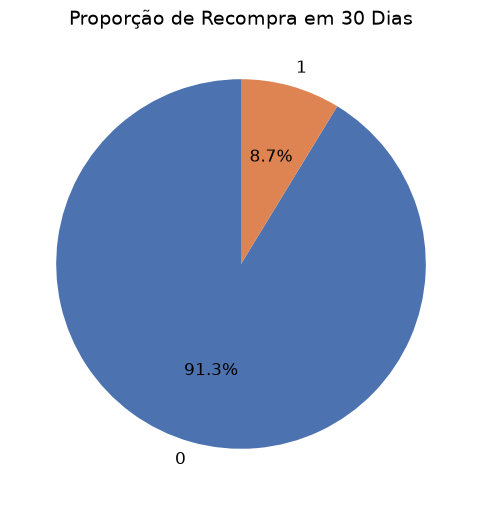

In [8]:
qtd_recomprado_em_30_dias = df_colunas_renomeadas['RECOMPRA_30D'].value_counts()
print(f"Quantidade de clientes que recompraram em 30 dias: {qtd_recomprado_em_30_dias}")

df_clientes_recompraram = df_colunas_renomeadas[df_colunas_renomeadas['RECOMPRA_30D'] == 1]
display(df_clientes_recompraram.head())

plt.figure(figsize=(6, 6))

# Gera o gráfico de pizza
qtd_recomprado_em_30_dias.plot(
    kind='pie', 
    autopct='%1.1f%%', # Mostra a porcentagem com 1 casa decimal
    colors=['#4C72B0', '#DD8452'],
    startangle=90,     # Começa a desenhar a partir do ângulo de 90 graus
    fontsize=12
)

plt.title('Proporção de Recompra em 30 Dias', fontsize=14)
plt.ylabel('') # Remove o rótulo do eixo Y para deixar mais limpo

plt.show()

### Atrasos, logística e atendimento

In [9]:
df_colunas_renomeadas['ATRASO_ENTREGA_DIAS'].value_counts()

ATRASO_ENTREGA_DIAS
2    646
1    615
3    525
0    277
4    270
5    116
6     34
7     14
8      3
Name: count, dtype: int64

In [10]:
df_atraso = df_colunas_renomeadas[df_colunas_renomeadas['ATRASO_ENTREGA_DIAS'] > 0]

df_atraso['REGIAO_CLIENTE'].value_counts()

REGIAO_CLIENTE
Sudeste         473
Sul             458
Norte           445
Nordeste        437
Centro-Oeste    410
Name: count, dtype: int64

In [11]:
media_geral = df_colunas_renomeadas.groupby('REGIAO_CLIENTE')['VALOR_FRETE'].mean()
media_atraso = df_atraso.groupby('REGIAO_CLIENTE')['VALOR_FRETE'].mean()

df_comparacao_frete = pd.DataFrame({
    'Frete Médio (Todos os Pedidos)': media_geral,
    'Frete Médio (Pedidos Atrasados)': media_atraso
})

display(df_comparacao_frete.round(2))

,Frete Médio (Todos os Pedidos),Frete Médio (Pedidos Atrasados)
REGIAO_CLIENTE,,
Centro-Oeste,37.87,37.64
Nordeste,37.25,37.34
Norte,38.98,39.01
Sudeste,38.50,38.64
Sul,38.40,38.13


In [12]:
df_atraso['CONTAGEM_RECLAMACOES'].value_counts()

CONTAGEM_RECLAMACOES
4     555
3     451
5     420
6     250
2     232
7     163
1      68
8      59
9      13
10     10
11      2
Name: count, dtype: int64

In [13]:
# Calcula a média, o máximo de dias de atraso e conta o volume de pedidos por tentativa
comparacao_tentativas = df_colunas_renomeadas.groupby('TENTATIVAS_ENTREGA')['ATRASO_ENTREGA_DIAS'].agg(
    Media_Dias_Atraso=('mean'),
    Max_Dias_Atraso=('max'),
    Total_Pedidos=('count')
).round(2)

display(comparacao_tentativas)

,Media_Dias_Atraso,Max_Dias_Atraso,Total_Pedidos
TENTATIVAS_ENTREGA,,,
1,2.15,8,824
2,2.25,8,838
3,2.16,8,838


In [14]:
df_colunas_renomeadas.head()

,ID_CLIENTE,IDADE_CLIENTE,REGIAO_CLIENTE,TEMPO_CLIENTE_MESES,ID_PEDIDO,VALOR_PEDIDO,QUANTIDADE_ITENS,VALOR_DESCONTO,PARCELAS_PAGAMENTO,TEMPO_ENTREGA_DIAS,ATRASO_ENTREGA_DIAS,VALOR_FRETE,TENTATIVAS_ENTREGA,CONTATOS_ATENDIMENTO,TEMPO_RESOLUCAO_DIAS,PONTUACAO_NPS,RECOMPRA_30D,CONTAGEM_RECLAMACOES,PONTUACAO_CSAT_INTERNO
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9


### Como vamos chamar cada faixa de NPS?

As notas da base têm casas decimais. Para comparar os pedidos, vou chamar de detrator a nota até 6, neutra a nota acima de 6 e até 8, e promotora a nota acima de 8. É a convenção usada nesta análise; as notas originais continuam sem arredondamento.

In [15]:
df_colunas_renomeadas['CATEGORIA_NPS'] = pd.cut(
    df_colunas_renomeadas['PONTUACAO_NPS'],
    bins=[-float('inf'), 6, 8, float('inf')],
    labels=['Detrator', 'Neutro', 'Promotor'],
)
resumo_nps = df_colunas_renomeadas['CATEGORIA_NPS'].value_counts().reindex(['Detrator', 'Neutro', 'Promotor']).to_frame('Pedidos')
resumo_nps['Percentual'] = resumo_nps['Pedidos'] / len(df_colunas_renomeadas) * 100
display(resumo_nps.round(1))

,Pedidos,Percentual
CATEGORIA_NPS,,
Detrator,1851,74.0
Neutro,448,17.9
Promotor,201,8.0


## 4. Fatores associados à satisfação do cliente

### 4.1 Quais fatores parecem mais críticos para a satisfação?

Para esta comparação usei Spearman, que ajuda a observar se duas variáveis tendem a subir ou cair juntas. Isso mostra associação, não causa; por isso, os números servem como pista para investigar a operação.

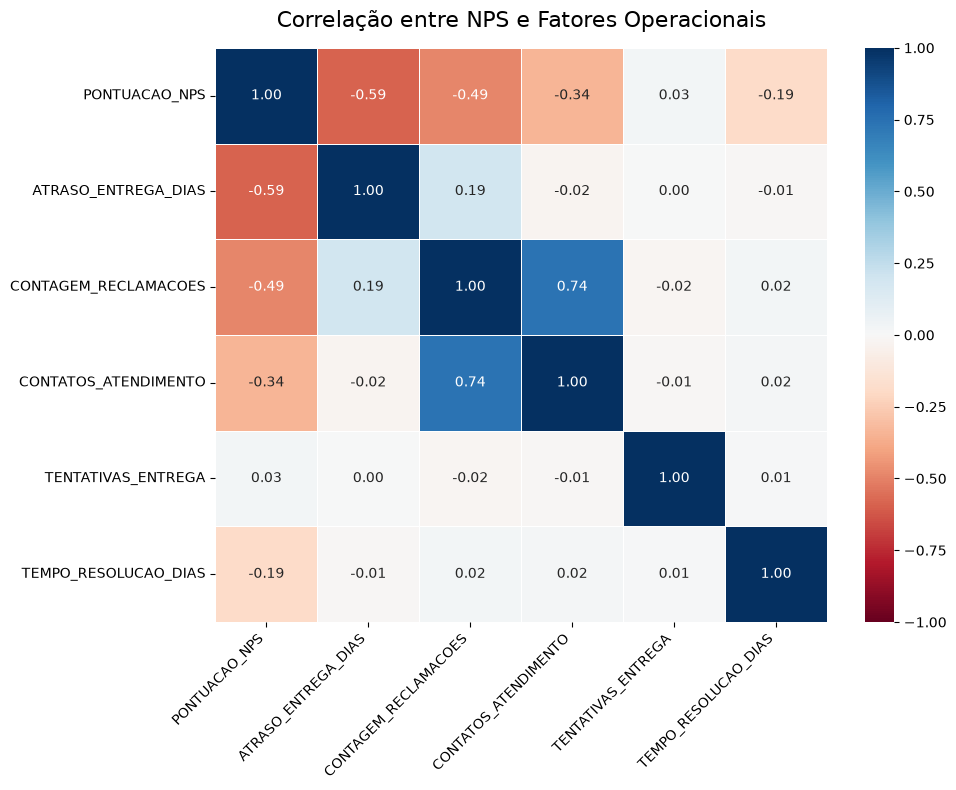


Impacto direto no NPS (do pior para o melhor):


ATRASO_ENTREGA_DIAS    -0.586217
CONTAGEM_RECLAMACOES   -0.490262
CONTATOS_ATENDIMENTO   -0.336385
TEMPO_RESOLUCAO_DIAS   -0.190330
TENTATIVAS_ENTREGA      0.026264
PONTUACAO_NPS           1.000000
Name: PONTUACAO_NPS, dtype: float64

,Variável,rho de Spearman,valor-p,pedidos
0,ATRASO_ENTREGA_DIAS,-0.586,1.09e-230,2500
1,CONTAGEM_RECLAMACOES,-0.490,2.48e-151,2500
2,CONTATOS_ATENDIMENTO,-0.336,3.44e-67,2500
4,TEMPO_RESOLUCAO_DIAS,-0.190,8.03e-22,2500
3,TENTATIVAS_ENTREGA,0.026,0.189,2500


In [16]:
colunas_analise_correlacao = [
    'PONTUACAO_NPS', 
    'ATRASO_ENTREGA_DIAS', 
    'CONTAGEM_RECLAMACOES', 
    'CONTATOS_ATENDIMENTO', 
    'TENTATIVAS_ENTREGA', 
    'TEMPO_RESOLUCAO_DIAS'
]

df_correlacao = df_colunas_renomeadas[colunas_analise_correlacao]

matriz_corr = df_correlacao.corr(method='spearman')

plt.figure(figsize=(10, 8))

sns.heatmap(
    matriz_corr, 
    annot=True,         # Exibe os números exatos dentro de cada quadrado
    cmap='RdBu',        # Paleta de cores: Vermelho (negativo) para Azul (positivo)
    fmt=".2f",          # Arredonda para 2 casas decimais
    linewidths=0.5,     # Linhas brancas separando os quadrados
    vmin=-1, vmax=1     # Trava a escala matemática de correlação entre -1 e 1
)

plt.title('Correlação entre NPS e Fatores Operacionais', fontsize=16, pad=15)
plt.xticks(rotation=45, ha='right') # Inclina os textos do eixo X para facilitar a leitura
plt.tight_layout()
plt.show()

# Opcional: Imprime apenas a coluna do NPS ordenada para ver os "maiores inimigos" rapidamente
print("\nImpacto direto no NPS (do pior para o melhor):")
display(matriz_corr['PONTUACAO_NPS'].sort_values(ascending=True))

# O rho ajuda a ver se duas variáveis tendem a subir ou cair juntas; valor-p não mede relevância para o negócio.
linhas_correlacao = []
for coluna in colunas_analise_correlacao[1:]:
    rho, p_valor = spearmanr(df_correlacao['PONTUACAO_NPS'], df_correlacao[coluna])
    linhas_correlacao.append({'Variável': coluna, 'rho de Spearman': rho, 'valor-p': p_valor, 'pedidos': len(df_correlacao)})
resumo_correlacao = pd.DataFrame(linhas_correlacao).sort_values('rho de Spearman')
display(resumo_correlacao.style.format({'rho de Spearman': '{:.3f}', 'valor-p': '{:.3g}'}))

### 4.2 O que mais gera detratores?

In [17]:
df_detrator = df_colunas_renomeadas.copy()

df_detrator['DETRATOR'] = df_detrator['PONTUACAO_NPS'].apply(lambda x: 1 if x <= 6 else 0)

df_detrator['TEVE_ATRASO'] = df_detrator['ATRASO_ENTREGA_DIAS'] > 0
df_detrator['TEVE_RECLAMACAO'] = df_detrator['CONTAGEM_RECLAMACOES'] > 0
df_detrator['MAIS_DE_1_TENTATIVA'] = df_detrator['TENTATIVAS_ENTREGA'] > 1

df_detrator.head()

,ID_CLIENTE,IDADE_CLIENTE,REGIAO_CLIENTE,TEMPO_CLIENTE_MESES,ID_PEDIDO,VALOR_PEDIDO,QUANTIDADE_ITENS,VALOR_DESCONTO,PARCELAS_PAGAMENTO,TEMPO_ENTREGA_DIAS,...,TEMPO_RESOLUCAO_DIAS,PONTUACAO_NPS,RECOMPRA_30D,CONTAGEM_RECLAMACOES,PONTUACAO_CSAT_INTERNO,CATEGORIA_NPS,DETRATOR,TEVE_ATRASO,TEVE_RECLAMACAO,MAIS_DE_1_TENTATIVA
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,...,4,6.9,0,3,6.5,Neutro,0,True,True,True
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,...,10,2.4,0,3,0.0,Detrator,1,True,True,True
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,...,5,4.8,0,7,1.5,Detrator,1,True,True,False
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,...,11,5.9,0,4,0.3,Detrator,1,True,True,True
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,...,0,6.1,0,3,7.9,Neutro,0,True,True,False


In [18]:
cenarios = {
    'Atraso na Entrega': 'TEVE_ATRASO',
    'Abriu Reclamação': 'TEVE_RECLAMACAO',
    'Mais de 1 Tentativa': 'MAIS_DE_1_TENTATIVA'
}

resultados = []
for nome_cenario, coluna_flag in cenarios.items():
    taxas = df_detrator.groupby(coluna_flag)['DETRATOR'].mean() * 100
    
    resultados.append({
        'Fator Operacional': nome_cenario,
        'Taxa de Detratores (Fluxo Ideal)': taxas.get(False, 0),
        'Taxa de Detratores (Com Problema)': taxas.get(True, 0)
    })
df_taxa_detratores = pd.DataFrame(resultados).set_index('Fator Operacional')

contagens_cenarios = []
for nome_cenario, coluna_flag in cenarios.items():
    contagens = df_detrator.groupby(coluna_flag)['DETRATOR'].size()
    contagens_cenarios.append({
        'Cenário': nome_cenario,
        'Sem ocorrência': int(contagens.get(False, 0)),
        'Com ocorrência': int(contagens.get(True, 0)),
    })

print("Comparação da Geração de Detratores (%):")
display(df_taxa_detratores.round(1))
display(pd.DataFrame(contagens_cenarios).set_index('Cenário'))

Comparação da Geração de Detratores (%):


,Taxa de Detratores (Fluxo Ideal),Taxa de Detratores (Com Problema)
Fator Operacional,,
Atraso na Entrega,36.5,78.7
Abriu Reclamação,4.3,74.7
Mais de 1 Tentativa,74.4,73.9


,Sem ocorrência,Com ocorrência
Cenário,,
Atraso na Entrega,277,2223
Abriu Reclamação,23,2477
Mais de 1 Tentativa,824,1676


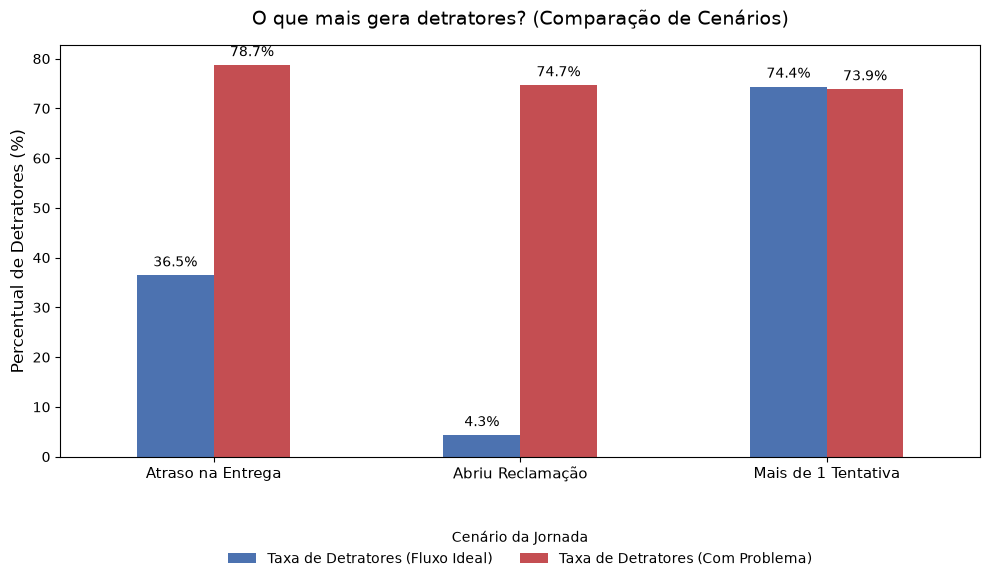

In [19]:
ax = df_taxa_detratores.plot(
    kind='bar', 
    figsize=(10, 6), 
    color=['#4C72B0', '#C44E52'] # Azul para Ideal, Vermelho para Problema
)

plt.title('O que mais gera detratores? (Comparação de Cenários)', fontsize=14, pad=15)
plt.ylabel('Percentual de Detratores (%)', fontsize=12)
plt.xlabel('')
plt.xticks(rotation=0, fontsize=11)
plt.legend(
    title='Cenário da Jornada', 
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), # Move para baixo do eixo X
    ncol=2,                      # Coloca os itens lado a lado
    frameon=False                # Remove a borda da caixa para ficar mais limpo
)
# Adiciona os números em cima de cada barra
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha = 'center', va = 'center', 
                xytext = (0, 9), 
                textcoords = 'offset points',
                fontsize=10)

plt.tight_layout()
plt.show()

### 4.3 Existe um ponto de ruptura na logística?

In [20]:
# Agrupa os dados pela quantidade de dias de atraso e calcula a média da nota NPS
media_nps_por_atraso = df_colunas_renomeadas.groupby('ATRASO_ENTREGA_DIAS')['PONTUACAO_NPS'].mean()

# Filtra para mostrar apenas do dia 0 (no prazo) até o dia 10 de atraso (para focar no principal)
tabela_ruptura = media_nps_por_atraso.head(11).round(2)

print("Média do NPS por dias de atraso:")
display(tabela_ruptura)

Média do NPS por dias de atraso:


ATRASO_ENTREGA_DIAS
0    6.86
1    5.55
2    4.58
3    3.44
4    2.44
5    1.48
6    1.10
7    0.29
8    0.00
Name: PONTUACAO_NPS, dtype: float64

A queda entre nenhum atraso e um dia de atraso chamou atenção. Para não olhar só para a média, a tabela abaixo também mostra quantos pedidos há em cada faixa e qual proporção ficou na categoria detratora. As faixas mais raras pedem mais cuidado na leitura.

In [21]:
def intervalo_wilson(sucessos, total):
    if total == 0:
        return float('nan'), float('nan')
    z = 1.96
    proporcao = sucessos / total
    denominador = 1 + z**2 / total
    centro = (proporcao + z**2 / (2 * total)) / denominador
    margem = z * (proporcao * (1 - proporcao) / total + z**2 / (4 * total**2)) ** 0.5 / denominador
    return centro - margem, centro + margem

resumo_atraso = df_colunas_renomeadas.groupby('ATRASO_ENTREGA_DIAS')['PONTUACAO_NPS'].agg(Pedidos='size', NPS_medio='mean')
grupo_atraso = df_colunas_renomeadas.groupby('ATRASO_ENTREGA_DIAS')['PONTUACAO_NPS']
resumo_atraso['Detratores (%)'] = grupo_atraso.apply(lambda notas: (notas <= 6).mean() * 100)
intervalos = grupo_atraso.apply(lambda notas: intervalo_wilson((notas <= 6).sum(), len(notas)))
resumo_atraso['IC 95% inferior (%)'] = intervalos.apply(lambda par: par[0] * 100)
resumo_atraso['IC 95% superior (%)'] = intervalos.apply(lambda par: par[1] * 100)
display(resumo_atraso.round(1))

,Pedidos,NPS_medio,Detratores (%),IC 95% inferior (%),IC 95% superior (%)
ATRASO_ENTREGA_DIAS,,,,,
0,277,6.9,36.5,31.0,42.3
1,615,5.5,59.7,55.7,63.5
2,646,4.6,75.4,71.9,78.6
3,525,3.4,89.7,86.8,92.0
4,270,2.4,95.9,92.9,97.7
5,116,1.5,99.1,95.3,99.8
6,34,1.1,100.0,89.8,100.0
7,14,0.3,100.0,78.5,100.0
8,3,0.0,100.0,43.8,100.0


### 4.4 Que tipo de cliente tem NPS mais alto ou mais baixo?

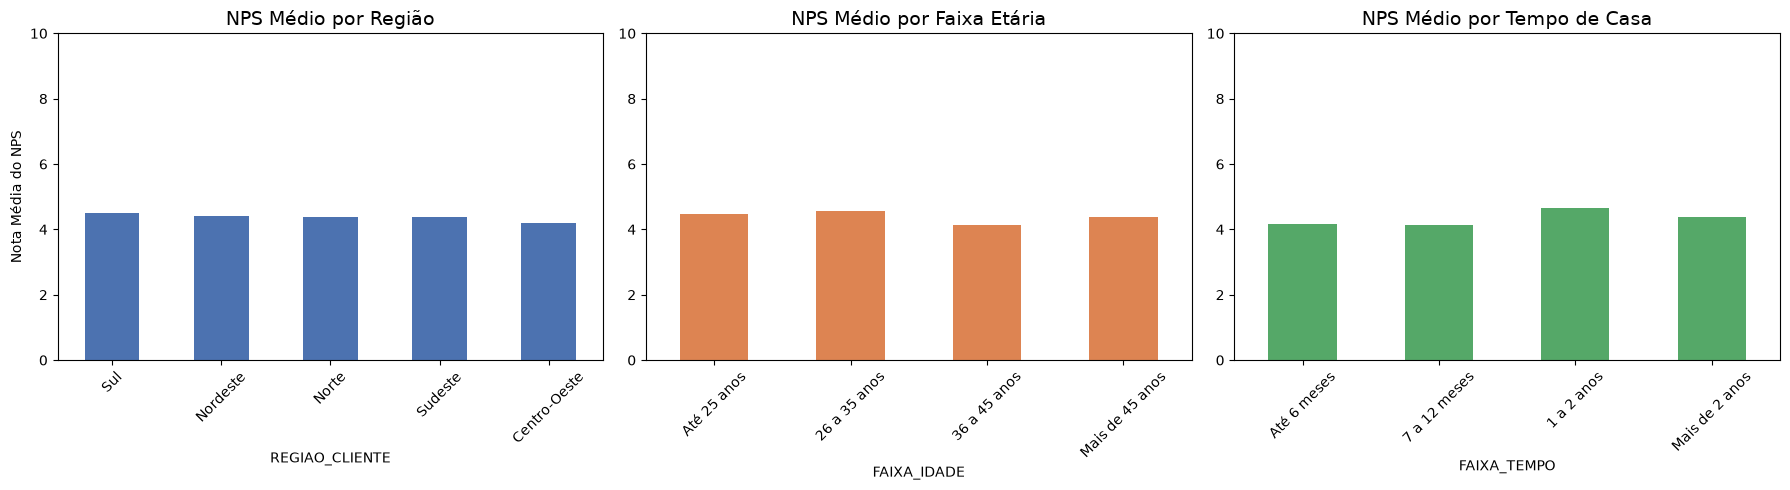

--- NPS POR REGIÃO ---


REGIAO_CLIENTE
Sul             4.49
Nordeste        4.42
Norte           4.38
Sudeste         4.37
Centro-Oeste    4.21
Name: PONTUACAO_NPS, dtype: float64


--- NPS POR FAIXA ETÁRIA ---


FAIXA_IDADE
Até 25 anos        4.48
26 a 35 anos       4.56
36 a 45 anos       4.12
Mais de 45 anos    4.39
Name: PONTUACAO_NPS, dtype: float64


--- NPS POR TEMPO DE RELACIONAMENTO ---


FAIXA_TEMPO
Até 6 meses       4.17
7 a 12 meses      4.12
1 a 2 anos        4.65
Mais de 2 anos    4.37
Name: PONTUACAO_NPS, dtype: float64

In [22]:
# 1. NPS por Região
nps_regiao = df_colunas_renomeadas.groupby('REGIAO_CLIENTE')['PONTUACAO_NPS'].mean().sort_values(ascending=False)

# 2. NPS por Faixa de Idade
# Criação das faixas etárias
bins_idade = [0, 25, 35, 45, 120]
labels_idade = ['Até 25 anos', '26 a 35 anos', '36 a 45 anos', 'Mais de 45 anos']
df_colunas_renomeadas['FAIXA_IDADE'] = pd.cut(df_colunas_renomeadas['IDADE_CLIENTE'], bins=bins_idade, labels=labels_idade)
nps_idade = df_colunas_renomeadas.groupby('FAIXA_IDADE', observed=False)['PONTUACAO_NPS'].mean()

# 3. NPS por Tempo de Relacionamento (Fidelidade)
# Criação das faixas de tempo de casa (em meses)
bins_tempo = [0, 6, 12, 24, 999]
labels_tempo = ['Até 6 meses', '7 a 12 meses', '1 a 2 anos', 'Mais de 2 anos']
df_colunas_renomeadas['FAIXA_TEMPO'] = pd.cut(df_colunas_renomeadas['TEMPO_CLIENTE_MESES'], bins=bins_tempo, labels=labels_tempo)
nps_tempo = df_colunas_renomeadas.groupby('FAIXA_TEMPO', observed=False)['PONTUACAO_NPS'].mean()

# --- Criando o Painel com os 3 Gráficos Lado a Lado ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico de Região
nps_regiao.plot(kind='bar', ax=axes[0], color='#4C72B0')
axes[0].set_title('NPS Médio por Região', fontsize=14)
axes[0].set_ylabel('Nota Média do NPS')
axes[0].set_ylim(0, 10) # Trava o eixo Y até 10 para ficar na escala do NPS
axes[0].tick_params(axis='x', rotation=45)

# Gráfico de Idade
nps_idade.plot(kind='bar', ax=axes[1], color='#DD8452')
axes[1].set_title('NPS Médio por Faixa Etária', fontsize=14)
axes[1].set_ylim(0, 10)
axes[1].tick_params(axis='x', rotation=45)

# Gráfico de Tempo de Casa
nps_tempo.plot(kind='bar', ax=axes[2], color='#55A868')
axes[2].set_title('NPS Médio por Tempo de Casa', fontsize=14)
axes[2].set_ylim(0, 10)
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Exibindo as tabelas de suporte para você ver os números exatos
print("--- NPS POR REGIÃO ---")
display(nps_regiao.round(2))
print("\n--- NPS POR FAIXA ETÁRIA ---")
display(nps_idade.round(2))
print("\n--- NPS POR TEMPO DE RELACIONAMENTO ---")
display(nps_tempo.round(2))

As médias do gráfico parecem próximas. Para olhar um pouco além delas, a tabela abaixo mostra quantos pedidos há em cada grupo e traz uma comparação exploratória entre as distribuições. Um resultado sem significância não prova que os grupos sejam iguais.

In [23]:
grupos_perfil = [('Região', 'REGIAO_CLIENTE'), ('Faixa etária', 'FAIXA_IDADE'), ('Tempo de relacionamento', 'FAIXA_TEMPO')]
resumo_perfil = []
for nome, coluna in grupos_perfil:
    tabela = df_colunas_renomeadas.groupby(coluna, observed=True)['PONTUACAO_NPS'].agg(['size', 'mean']).reset_index()
    teste = kruskal(*(grupo['PONTUACAO_NPS'].to_numpy() for _, grupo in df_colunas_renomeadas.groupby(coluna, observed=True)))
    resumo_perfil.append({'Dimensão': nome, 'H de Kruskal-Wallis': teste.statistic, 'valor-p': teste.pvalue})
    tabela.insert(0, 'Dimensão', nome)
    resumo_perfil[-1]['Grupos'] = len(tabela)
    display(tabela.rename(columns={coluna: 'Grupo', 'size': 'Pedidos', 'mean': 'NPS médio'}).round(2))
display(pd.DataFrame(resumo_perfil).style.format({'H de Kruskal-Wallis': '{:.2f}', 'valor-p': '{:.3f}'}))

,Dimensão,Grupo,Pedidos,NPS médio
0,Região,Centro-Oeste,468,4.21
1,Região,Nordeste,485,4.42
2,Região,Norte,506,4.38
3,Região,Sudeste,520,4.37
4,Região,Sul,521,4.49


,Dimensão,Grupo,Pedidos,NPS médio
0,Faixa etária,Até 25 anos,389,4.48
1,Faixa etária,26 a 35 anos,465,4.56
2,Faixa etária,36 a 45 anos,517,4.12
3,Faixa etária,Mais de 45 anos,1129,4.39


,Dimensão,Grupo,Pedidos,NPS médio
0,Tempo de relacionamento,Até 6 meses,122,4.17
1,Tempo de relacionamento,7 a 12 meses,120,4.12
2,Tempo de relacionamento,1 a 2 anos,247,4.65
3,Tempo de relacionamento,Mais de 2 anos,2011,4.37


,Dimensão,H de Kruskal-Wallis,valor-p,Grupos
0,Região,3.38,0.497,5
1,Faixa etária,7.50,0.058,4
2,Tempo de relacionamento,4.78,0.189,4


### 4.5 O NPS influencia a recompra?

A recompra aparece no começo da exploração porque ajuda a conectar satisfação e comportamento. Como as notas têm casas decimais, usaremos a convenção explicada acima; depois, vale conferir se essa relação aparece mesmo nos dados ou se foi criada pela forma como a base foi montada.

Taxa de Recompra em 30 Dias por Categoria NPS:


CATEGORIA_NPS
Detrator (0-6)       0.0%
Neutro (7-8)         3.8%
Promotor (9-10)    100.0%
Name: RECOMPRA_30D, dtype: str

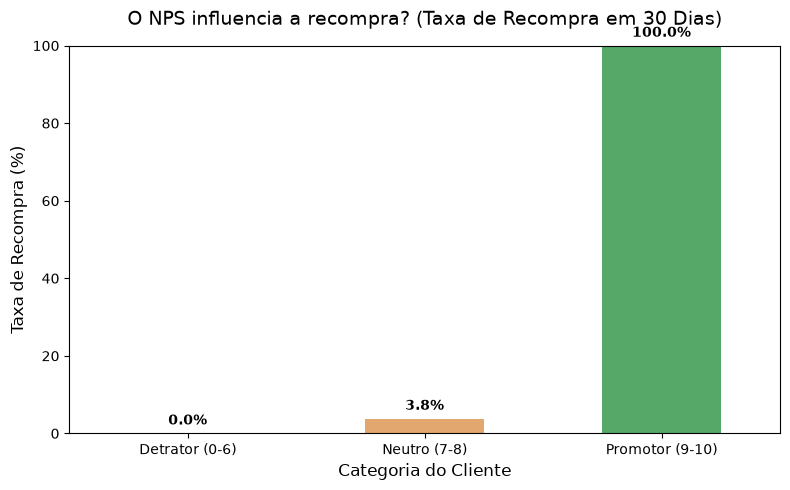

In [24]:
# 1. Função para classificar as notas nas 3 categorias oficiais do NPS
def classificar_nps(nota):
    if nota <= 6:
        return 'Detrator (0-6)'
    elif nota <= 8:
        return 'Neutro (7-8)'
    else:
        return 'Promotor (9-10)'

# Cria a nova coluna de categoria
df_colunas_renomeadas['CATEGORIA_NPS'] = df_colunas_renomeadas['PONTUACAO_NPS'].apply(classificar_nps)

# 2. Calcula a taxa de recompra (média * 100)
taxa_recompra = df_colunas_renomeadas.groupby('CATEGORIA_NPS')['RECOMPRA_30D'].mean() * 100

# Ordena do pior para o melhor para o gráfico fazer sentido lógico
ordem_nps = ['Detrator (0-6)', 'Neutro (7-8)', 'Promotor (9-10)']
taxa_recompra = taxa_recompra.reindex(ordem_nps)

# Exibe a tabela com os resultados exatos
print("Taxa de Recompra em 30 Dias por Categoria NPS:")
display(taxa_recompra.round(1).astype(str) + '%')

# 3. Cria o Gráfico de Barras com cores semânticas
plt.figure(figsize=(8, 5))
cores = ['#C44E52', '#E2A76F', '#55A868'] # Vermelho, Laranja/Amarelo, Verde
ax = taxa_recompra.plot(kind='bar', color=cores)

plt.title('O NPS influencia a recompra? (Taxa de Recompra em 30 Dias)', fontsize=14, pad=15)
plt.xlabel('Categoria do Cliente', fontsize=12)
plt.ylabel('Taxa de Recompra (%)', fontsize=12)
plt.xticks(rotation=0)
plt.ylim(0, 100) # Mantém o eixo Y até 100% para evitar distorções visuais

# Adiciona as porcentagens exatas no topo das barras
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha = 'center', va = 'center', 
                xytext = (0, 9), 
                textcoords = 'offset points',
                fontweight='bold')

plt.tight_layout()
plt.show()

In [25]:
print('Pedidos por categoria e recompra (0 = não, 1 = sim):')
display(pd.crosstab(df_colunas_renomeadas['CATEGORIA_NPS'], df_colunas_renomeadas['RECOMPRA_30D'], margins=True))
recompra_bate_com_nps = (df_colunas_renomeadas['RECOMPRA_30D'] == (df_colunas_renomeadas['PONTUACAO_NPS'] >= 8).astype(int)).all()
print(f'A recompra coincide com a regra PONTUACAO_NPS >= 8 em todos os pedidos? {recompra_bate_com_nps}')

Pedidos por categoria e recompra (0 = não, 1 = sim):


RECOMPRA_30D,0,1,All
CATEGORIA_NPS,,,
Detrator (0-6),1851,0,1851
Neutro (7-8),431,17,448
Promotor (9-10),0,201,201
All,2282,218,2500


A recompra coincide com a regra PONTUACAO_NPS >= 8 em todos os pedidos? True


Na base, a recompra coincide perfeitamente com a regra da nota. Isso é um sinal de que as duas colunas podem ter sido geradas em conjunto. Então, apesar de a comparação ser interessante, esses percentuais não devem ser usados para prometer retenção ou calcular retorno financeiro.

### 4.6 O atendimento é um gargalo?

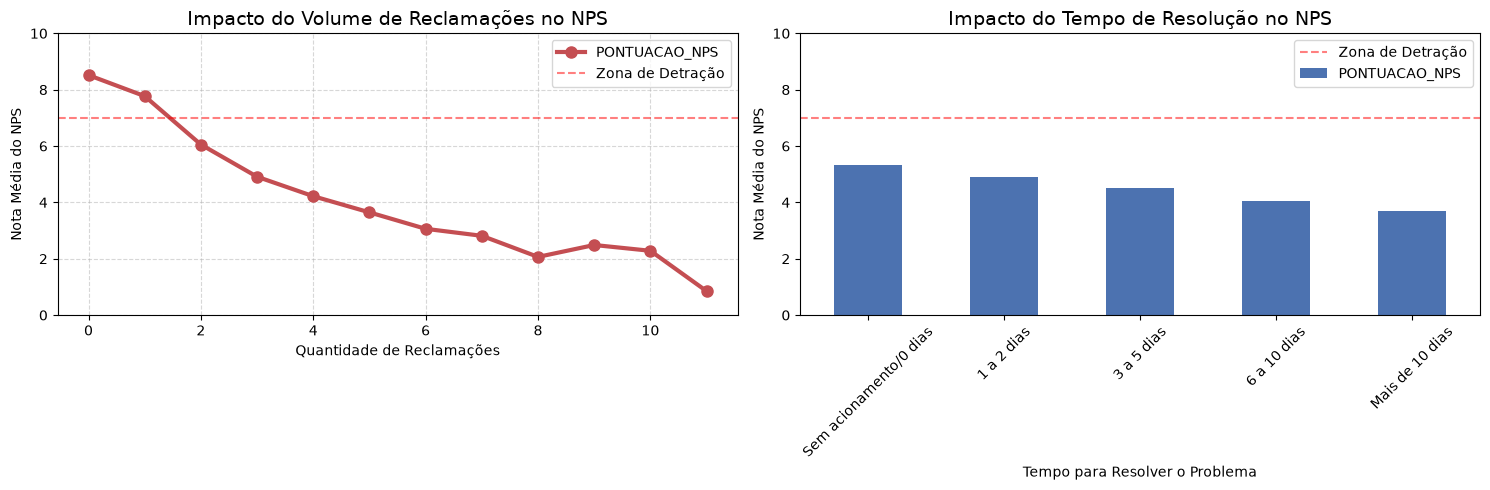

--- NPS POR QUANTIDADE DE RECLAMAÇÕES ---


CONTAGEM_RECLAMACOES
0     8.52
1     7.77
2     6.05
3     4.91
4     4.22
5     3.65
6     3.06
7     2.81
8     2.07
9     2.49
10    2.28
11    0.85
Name: PONTUACAO_NPS, dtype: float64


--- NPS POR TEMPO DE RESOLUÇÃO (DIAS) ---


FAIXA_TEMPO_RESOLUCAO
Sem acionamento/0 dias    5.32
1 a 2 dias                4.90
3 a 5 dias                4.51
6 a 10 dias               4.04
Mais de 10 dias           3.68
Name: PONTUACAO_NPS, dtype: float64

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Agrupar NPS por Quantidade de Reclamações
nps_por_reclamacao = df_colunas_renomeadas.groupby('CONTAGEM_RECLAMACOES')['PONTUACAO_NPS'].mean()

# 2. Criar faixas para o Tempo de Resolução e calcular a média do NPS
bins_tempo = [-1, 0, 2, 5, 10, 999] # -1 a 0 garante que quem não teve dias de resolução (0) entre na primeira faixa
labels_tempo = ['Sem acionamento/0 dias', '1 a 2 dias', '3 a 5 dias', '6 a 10 dias', 'Mais de 10 dias']

df_colunas_renomeadas['FAIXA_TEMPO_RESOLUCAO'] = pd.cut(
    df_colunas_renomeadas['TEMPO_RESOLUCAO_DIAS'], 
    bins=bins_tempo, 
    labels=labels_tempo
)

nps_por_tempo = df_colunas_renomeadas.groupby('FAIXA_TEMPO_RESOLUCAO', observed=False)['PONTUACAO_NPS'].mean()

# --- Criando o Painel com 2 Gráficos Lado a Lado ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico 1: Impacto das Reclamações
nps_por_reclamacao.plot(kind='line', marker='o', ax=axes[0], color='#C44E52', linewidth=3, markersize=8)
axes[0].set_title('Impacto do Volume de Reclamações no NPS', fontsize=14)
axes[0].set_ylabel('Nota Média do NPS')
axes[0].set_xlabel('Quantidade de Reclamações')
axes[0].set_ylim(0, 10)
axes[0].axhline(y=6.99, color='red', linestyle='--', alpha=0.5, label='Zona de Detração')
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend()

# Gráfico 2: Impacto do Tempo de Resolução
nps_por_tempo.plot(kind='bar', ax=axes[1], color='#4C72B0')
axes[1].set_title('Impacto do Tempo de Resolução no NPS', fontsize=14)
axes[1].set_ylabel('Nota Média do NPS')
axes[1].set_xlabel('Tempo para Resolver o Problema')
axes[1].set_ylim(0, 10)
axes[1].axhline(y=6.99, color='red', linestyle='--', alpha=0.5, label='Zona de Detração')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend()

plt.tight_layout()
plt.show()

# Exibindo os números exatos
print("--- NPS POR QUANTIDADE DE RECLAMAÇÕES ---")
display(nps_por_reclamacao.round(2))
print("\n--- NPS POR TEMPO DE RESOLUÇÃO (DIAS) ---")
display(nps_por_tempo.round(2))

O gráfico ajuda a enxergar o caminho, mas alguns números de reclamações aparecem poucas vezes. A tabela abaixo traz as quantidades e ajuda a separar um padrão consistente de um resultado baseado em poucos pedidos.

In [27]:
def resumir_faixa_atendimento(grupo):
    total = len(grupo)
    detratores = int((grupo['PONTUACAO_NPS'] <= 6).sum())
    limite_inferior, limite_superior = intervalo_wilson(detratores, total)
    return pd.Series({
        'Pedidos': total,
        'NPS médio': grupo['PONTUACAO_NPS'].mean(),
        'Detratores (%)': detratores / total * 100,
        'IC 95% inferior (%)': limite_inferior * 100,
        'IC 95% superior (%)': limite_superior * 100,
    })

print('Por número de reclamações:')
display(
    df_colunas_renomeadas.groupby('CONTAGEM_RECLAMACOES', observed=True)
    .apply(resumir_faixa_atendimento)
    .round(1)
)
print('Por tempo de resolução:')
display(
    df_colunas_renomeadas.groupby('FAIXA_TEMPO_RESOLUCAO', observed=True)
    .apply(resumir_faixa_atendimento)
    .round(1)
)

Por número de reclamações:


,Pedidos,NPS médio,Detratores (%),IC 95% inferior (%),IC 95% superior (%)
CONTAGEM_RECLAMACOES,,,,,
0,23.0,8.5,4.3,0.8,21.0
1,122.0,7.8,8.2,4.5,14.4
2,277.0,6.1,43.3,37.6,49.2
3,507.0,4.9,67.7,63.5,71.6
4,600.0,4.2,81.2,77.8,84.1
5,444.0,3.6,88.3,85.0,91.0
6,266.0,3.1,93.6,90.0,96.0
7,169.0,2.8,93.5,88.7,96.3
8,63.0,2.1,100.0,94.3,100.0


Por tempo de resolução:


,Pedidos,NPS médio,Detratores (%),IC 95% inferior (%),IC 95% superior (%)
FAIXA_TEMPO_RESOLUCAO,,,,,
Sem acionamento/0 dias,208.0,5.3,60.1,53.3,66.5
1 a 2 dias,421.0,4.9,66.3,61.6,70.6
3 a 5 dias,619.0,4.5,73.2,69.6,76.5
6 a 10 dias,1038.0,4.0,78.4,75.8,80.8
Mais de 10 dias,214.0,3.7,84.1,78.6,88.4


## Fechando a análise

Olhando para o conjunto dos resultados, atraso e reclamações são os sinais que mais chamam atenção. A nota média cai já no primeiro dia de atraso e a proporção de detratores cresce conforme o número de reclamações aumenta. São bons pontos de partida para conversar com logística e atendimento — não uma prova de que uma única mudança, sozinha, vai elevar o NPS.

Sobre o perfil, as diferenças observadas entre regiões e tempos de relacionamento não foram claras nesta amostra; a comparação por idade ficou perto do limite usado no teste. Por isso, eu evitaria dizer que todos os clientes são iguais ou que características demográficas nunca importam.

Por fim, a recompra acompanha perfeitamente um corte da nota nesta base. Antes de tirar conclusões de negócio, precisamos confirmar como esse campo foi produzido. O próximo passo mais útil é validar as inconsistências com a origem dos dados e repetir a análise em registros reais, com datas e contexto da pesquisa.